In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    BaggingClassifier,
    RandomForestClassifier,
    GradientBoostingClassifier,
)

In [2]:
COLS = ["age", "workclass", "fnlwgt", "education", "education-num",
        "marital-status", "occupation", "relationship", "race", "sex",
        "capital-gain", "capital-loss", "hours-per-week", "native-country", "income"]

DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"
TEST_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.test"

def load_adult(url):
    first = pd.read_csv(url, nrows=1, header=None, comment="|", skipinitialspace=True).iloc[0, 0]
    header = 0 if str(first).strip().lower() == "age" else None
    df = pd.read_csv(url, header=header, names=None if header == 0 else COLS,
                     na_values=["?"], skipinitialspace=True, comment="|")
    if df.shape[1] == len(COLS):
        df.columns = COLS
    df["income"] = df["income"].astype(str).str.strip().str.rstrip(".")
    df = df[df["income"].isin(["<=50K", ">50K"])]
    df["income"] = (df["income"] == ">50K").astype(int)
    return df

df_all = pd.concat([load_adult(DATA_URL), load_adult(TEST_URL)], ignore_index=True)
print(df_all.shape)

(48842, 15)


In [3]:
NUM_COLS = ["age", "fnlwgt", "education-num", "capital-gain", "capital-loss", "hours-per-week"]
CAT_COLS = [c for c in COLS if c not in NUM_COLS + ["income"]]

def preprocess(train_df, test_df):
    X_tr = train_df.drop(columns="income").copy()
    y_tr = train_df["income"].values
    med = {c: X_tr[c].median() for c in NUM_COLS}

    X_tr[NUM_COLS] = X_tr[NUM_COLS].fillna(med)
    X_tr[CAT_COLS] = X_tr[CAT_COLS].fillna("Unknown")
    X_tr = pd.get_dummies(X_tr, columns=CAT_COLS)

    X_te = test_df.drop(columns="income").copy()
    y_te = test_df["income"].values
    X_te[NUM_COLS] = X_te[NUM_COLS].fillna(med)
    X_te[CAT_COLS] = X_te[CAT_COLS].fillna("Unknown")
    X_te = pd.get_dummies(X_te, columns=CAT_COLS)
    X_te = X_te.reindex(columns=X_tr.columns, fill_value=0)

    return X_tr.values.astype(float), y_tr, X_te.values.astype(float), y_te

In [4]:
TECHNIQUE      = "random_forest"
TRAIN_SIZE     = 0.8
BASE_DEPTH     = 8
RANDOM_STATE   = 42

def calc_metrics(y_true, y_pred):
    return {
        "accuracy":  accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "recall":    recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "f1":        f1_score(y_true, y_pred, pos_label=1, zero_division=0),
    }

def make_model(technique, n_estimators, seed=RANDOM_STATE):
    if technique == "bagging":
        return BaggingClassifier(
            estimator=DecisionTreeClassifier(max_depth=BASE_DEPTH),
            n_estimators=n_estimators,
            max_samples=0.8,
            n_jobs=-1, random_state=seed,
        )
    if technique == "random_forest":
        return RandomForestClassifier(
            n_estimators=n_estimators,
            max_depth=BASE_DEPTH,
            max_features="sqrt",
            n_jobs=-1, random_state=seed,
        )
    if technique == "boosting":
        return GradientBoostingClassifier(
            n_estimators=n_estimators,
            max_depth=3,
            learning_rate=0.1,
            random_state=seed,
        )
    raise ValueError(f"Неизвестная техника: {technique}")

In [6]:
train_df, test_df = train_test_split(
    df_all, train_size=TRAIN_SIZE, stratify=df_all["income"], random_state=RANDOM_STATE
)
X_train, y_train, X_test, y_test = preprocess(train_df, test_df)

dt = DecisionTreeClassifier(max_depth=BASE_DEPTH, random_state=RANDOM_STATE)
dt.fit(X_train, y_train)
dt_metrics = calc_metrics(y_test, dt.predict(X_test))

print("Одиночное дерево:")
print(pd.Series(dt_metrics).round(4))

Одиночное дерево:
accuracy     0.8578
precision    0.7982
recall       0.5432
f1           0.6465
dtype: float64


In [7]:
n_list = list(range(50, 101, 10))
techniques = ["bagging", "random_forest", "boosting"]

rows = []
for tech in techniques:
    for n in n_list:
        model = make_model(tech, n).fit(X_train, y_train)
        m = calc_metrics(y_test, model.predict(X_test))
        rows.append({"technique": tech, "n_estimators": n, **m})
        print(f"{tech:14s} n={n:3d}  " + "  ".join(f"{k}={v:.4f}" for k, v in m.items()))

results = pd.DataFrame(rows)
results.to_csv("ensemble_results.csv", index=False)
results

bagging        n= 50  accuracy=0.8622  precision=0.7880  recall=0.5804  f1=0.6685
bagging        n= 60  accuracy=0.8621  precision=0.7893  recall=0.5783  f1=0.6675
bagging        n= 70  accuracy=0.8595  precision=0.7933  recall=0.5582  f1=0.6553
bagging        n= 80  accuracy=0.8600  precision=0.7954  recall=0.5586  f1=0.6563
bagging        n= 90  accuracy=0.8595  precision=0.7930  recall=0.5586  f1=0.6555
bagging        n=100  accuracy=0.8601  precision=0.7923  recall=0.5629  f1=0.6582
random_forest  n= 50  accuracy=0.8504  precision=0.7838  recall=0.5180  f1=0.6237
random_forest  n= 60  accuracy=0.8509  precision=0.7855  recall=0.5184  f1=0.6246
random_forest  n= 70  accuracy=0.8513  precision=0.7875  recall=0.5184  f1=0.6252
random_forest  n= 80  accuracy=0.8512  precision=0.7859  recall=0.5197  f1=0.6256
random_forest  n= 90  accuracy=0.8523  precision=0.7856  recall=0.5265  f1=0.6305
random_forest  n=100  accuracy=0.8534  precision=0.7889  recall=0.5291  f1=0.6334
boosting       n

,technique,n_estimators,accuracy,precision,recall,f1
0,bagging,50,0.862217,0.788037,0.580411,0.668473
1,bagging,60,0.862115,0.789259,0.578272,0.667490
2,bagging,70,0.859453,0.793313,0.558169,0.655285
3,bagging,80,0.859965,0.795371,0.558597,0.656281
4,bagging,90,0.859453,0.792957,0.558597,0.655458
5,bagging,100,0.860068,0.792294,0.562874,0.658165
6,random_forest,50,0.850445,0.783819,0.517964,0.623745
7,random_forest,60,0.850855,0.785483,0.518392,0.624581
8,random_forest,70,0.851264,0.787524,0.518392,0.625226
9,random_forest,80,0.851162,0.785899,0.519675,0.625644


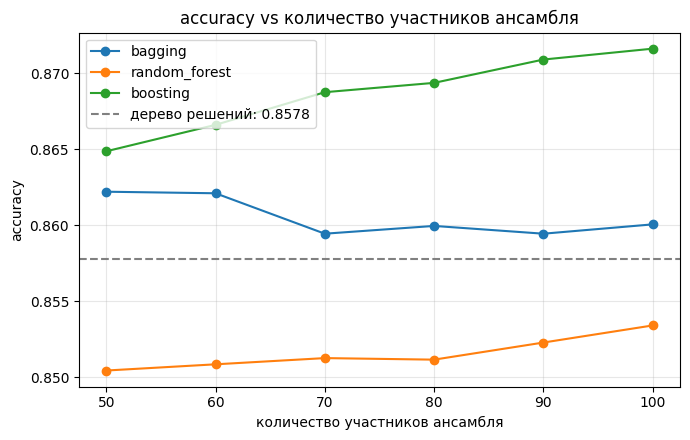

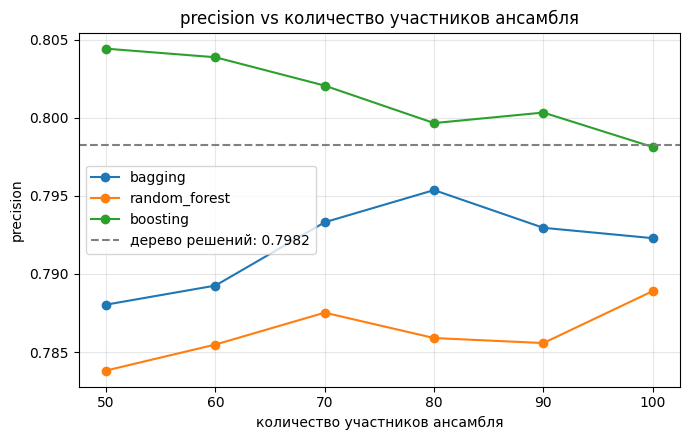

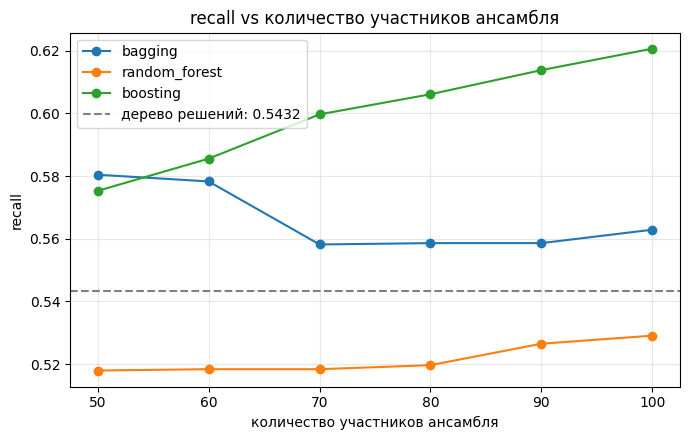

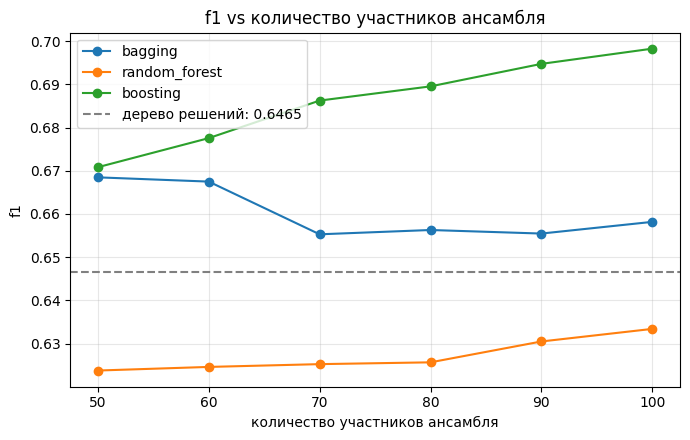

In [8]:
for metric in ["accuracy", "precision", "recall", "f1"]:
    plt.figure(figsize=(7, 4.5))

    for tech in techniques:
        g = results[results.technique == tech].sort_values("n_estimators")
        plt.plot(g.n_estimators, g[metric], marker="o", label=tech)

    plt.axhline(dt_metrics[metric], color="gray", ls="--",
                label=f"дерево решений: {dt_metrics[metric]:.4f}")

    plt.title(f"{metric} vs количество участников ансамбля")
    plt.xlabel("количество участников ансамбля")
    plt.ylabel(metric)
    plt.xticks(n_list)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()